In [ ]:
import matplotlib
# matplotlib.use('Agg') # 这里设置使用Agg后端，可以在没有显示环境的服务器上生成图像
# 如果不适用Agg后端，可能会遇到以下错误：
# RuntimeError: Invalid DISPLAY variable
import matplotlib.pyplot as plt
import numpy as np

print("Matplotlib backend:", matplotlib.get_backend())
# 生成一些示例数据
x = np.linspace(0, 10, 100)
y = np.sin(x)

# 绘制折线图
plt.plot(x, y)
plt.xlabel('x')  # 设置x轴标签
plt.ylabel('sin(x)')  # 设置y轴标签
plt.title('Sine Wave')  # 设置图表标题
plt.show()

# 绘制散点图
# 生成随机数
x = np.random.rand(100) * 10  # 生成100个0到10之间的随机数
y = np.sin(x) + np.random.normal(0, 0.2, 100)  # 在sin(x)的基础上添加一些随机噪声
plt.scatter(x, y, s=10)  # s参数设置点的大小
plt.xlabel('x')  # 设置x轴标签
plt.ylabel('sin(x)')  # 设置y轴标签
plt.title('Sine Wave Scatter')  # 设置图表标题
plt.show()
# 设置x范围和y范围
# plt.xlim(0, 10)  # 设置x轴范围为0到10
# plt.ylim(-1.5, 1.5)  # 设置y轴范围为-1.5到1.5
# plt.plot(x, y)  # 绘制折线图
# plt.xlabel('x')  # 设置x轴标签
# plt.ylabel('sin(x)')  # 设置y轴标签
# plt.title('Sine Wave with Limits')  # 设置图表标题
# plt.show()


# 绘制柱状体
plt.bar(['A', 'B', 'C'], [3, 7, 1])  # 绘制柱状图，x轴为['A', 'B', 'C']，y轴为[3, 7, 1]
plt.xlabel('Categories')  # 设置x轴标签
plt.ylabel('Values')  # 设置y轴标签
plt.title('Bar Chart')  # 设置图表标题
plt.show()


# 使用step()绘制图阶梯图
x = np.linspace(0, 10, 100)
y1 = x**2  
y2 = x
plt.figure(figsize=(4,10))  # 这里会创建一个新的图形，并设置图形的大小为10x4英寸
plt.step(x, y1, label='x^2-before', )  # 绘制阶梯图，并设置标签，默认情况下，阶梯图在x值之前改，每段间隔
plt.step(x, y1, label='x^2-after', where='post', )  # 绘制分段折线图，并设置标签，
# sept函数无法直接设置步长，更适合绘制离散数据
plt.plot(x, y1, label='x^2')  # 绘制折现图，并设置标签
plt.xlim(0, 4)  # 设置x轴范围为0到10
plt.ylim(0, 10)  # 设置y轴范围为-1.5到1.5
plt.xlabel('x')  # 设置x轴标签
plt.ylabel('Value')  # 设置y轴标签
plt.title('Sine and Cosine Waves')  # 设置图表标题
plt.legend()  # 显示图例
plt.show()

# 离散数据阶梯图示例
x = np.arange(10)
y = np.random.randint(0, 10, 10)
plt.plot(x, y, label='Line Plot', linestyle='--')  # 绘制折线图，设置为虚线
plt.step(x, y, label='Step Plot', where='pre')  # 绘制阶梯图，设置where参数为'pre'表示阶梯图在x值之前改变
plt.step(x, y, label='Step Plot', where='post')  # 绘制阶梯图，设置where参数为'post'表示阶梯图在x值之后改变
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.title('Simple Step Plot - how2matplotlib.com')
plt.legend()
plt.show()

# 以‌取整函数为例
x = np.linspace(0, 10, 100) # 生成0到10之间的100个点
y = np.floor(x)  # 取整函数
plt.step(x, y, where='post')  # where参数设置阶梯图的位置，这里设置为'post'表示阶梯图在x值之后改变
plt.xlabel('x')  # 设置x轴标签
plt.ylabel('floor(x)')  # 设置y轴标签
plt.title('Step Function')  # 设置图表标题
plt.show()


# 绘制饼图
labels = ['A', 'B', 'C', 'D']  # 定义标签
sizes = [15, 30, 45, 10]  # 定义每个部分的大小
plt.pie([15, 30, 45, 10], labels=['A', 'B', 'C', 'D'], autopct='%1.1f%%')  # 绘制饼图，autopct参数设置显示百分比，格式为1位小数
plt.title('Pie Chart')  # 设置图表标题
plt.show()

![alt text](image/MatplotlibStructure.png)

## 绘制等高线图

plt.contour(X, Y, Z, levels=25, cmap="viridis")

核心参数：X坐标矩阵、Y坐标矩阵、以及对应的Z高度矩阵

本质是绘制 $Z = F(X,Y)$ 的函数图像

levels参数指定等高线条数(需要分多少份高度差距)，cmap参数指定颜色映射

为了让图表边缘的坐标轴标签（或者图例）好看，Matplotlib 内部调用了一个叫 MaxNLocator 的工具。它的逻辑是：
viridis
1. 找出 $Z$（Loss）的最小值和最大值。

2. 尽量在这个范围内划分出大约 25 个层级。

3. 强制要求这些层级的值必须是“整数”或“漂亮的刻度”（比如末尾是 1, 2, 5, 10 的倍数）。

所以，levels=25 真正的意思是：“请帮我画大约 25 条等高线，间距尽量均匀，但数值必须是漂亮的整数。”（实际画出来的可能是 24 条、25 条或 26 条）。

如果你不想让 Matplotlib 自作主张，想完全由自己控制等高线的划分方式，你可以把一个数组（List 或 Numpy Array）传给 levels，而不是传整数。

情况 A：我偏要绝对的等差数列（严格等分）

```python
    # 生成从 min 到 max 严格等距的 25 个数
    my_levels = np.linspace(Z.min(), Z.max(), 25)
    plt.contour(W1, W2, Z, levels=my_levels, cmap="viridis")
```

情况 B：更专业的画法（对数等分 - Logspace）<br>
在深度学习中，由于碗壁太陡，碗底太太平，普通的等高线往往看不清谷底（最优解附近）的细节。我们通常会让等高线的间距呈对数分布（外圈跨度大，内圈跨度小），这样能极大地看清模型在谷底是如何收敛的：

```Python
    # 按照对数比例生成 25 个层级，让谷底的等高线更密集
    my_levels = np.logspace(np.log10(Z.min()), np.log10(Z.max()), 25)
    plt.contour(W1, W2, Z, levels=my_levels, cmap="viridis")
```

<br>

### 等高线图绘制流程描述 - 以房价预测为例
1. 得到x1，x2的样本数据(目前是人造的)，可以理解为房子的价格和地段（或其中任意两个因素）的数值化表达
2. 生成初始的w1、w2参数（可以自定义，可随机）
3. 通过样本数据 + 损失函数 + 优化方法开始训练，得到训练过程中不断迭代的损失值(平均) 和 迭代过程中所有产生的w1，w2值
4. 得到所有迭代的w1，w2中的最大，最小值，在最大最小值之间进行均分(100份或其他数字，划分份数越多图表绘制越精细)
5. 通过np.meshgrid函数生成网格坐标矩阵

    np.meshgrid(x, y)

    其原理是将输入的一维数组x和y分别复制成二维矩阵X和Y，其中X的每一行都是x的副本，Y的每一列都是y的副本，这样就形成了一个网格坐标矩阵

6. 得到三维坐标中的x，y骨架后，需要再获得具体x，y数据对应的z值

    在该案例中，对应的z值为loss(损失)值，Z = ((pred_grid - y_np[:, None, None]) ** 2).mean(axis=0) / 2

    - 它把刚才算出的 一千万个预测值，减去真实的标签 y，求平方

    - 然后 .mean(axis=0) 沿着第0维（即1000个样本那一维）求平均值。

    - 三维 (1000, 100, 100) 经过 mean 之后，变成了二维 (100, 100)

7. plt.contour(X, Y, Z) 绘制等高线图

    contour(X, Y, Z) 其实是在表达一个函数：Z = f (X, Y)，其中X，Y，Z分别代表X坐标矩阵、Y坐标矩阵、以及对应的Z高度矩阵.
    
    在此案例中，X轴是参数 $w_1$，Y轴是参数 $w_2$，Z轴是损失值（Loss）
    
这里绘制出的等高线本质就是在由X，Y网格坐标矩阵构成的网格线上找出Z值等于等高线的点逐一连接起来，本质上是多条折现，但是如果划分区域够细的话就会成弧线形状

绘制等高线的本质，就是在 X、Y 构成的棋盘网格上，根据每个格点的 Z 高度，在格子之间**估算（插值）**出高度恰好等于等高线数值的点，然后把它们连起来。因为这些点是在格子里连线的，所以本质上它是一条条多边形折线。但只要我们的网格划分得足够密（比如 100x100 甚至更细），这些折线的拐角就会非常小，在视觉上看起来就是平滑的曲线了。

等高线的绘制算法（如 Marching Squares）本质上是对离散网格数据的等值线提取。它在由 X、Y 坐标矩阵构成的二维网格面内，通过对相邻网格点上的 Z 值进行线性插值，计算出特定层级（Level）的等值点，并将其依次连接成闭合的折线（Polyline）。虽然其底层几何结构是分段线性折线，但当网格分辨率（Resolution）足够高时，由量变引起质变，折线在视觉上便逼近了平滑的弧线。

arrayX: [0 1 2 3 4 5 6 7 8 9]
arrayY: [10 12 14 16 18 20 22 24 26 28]
arrayX: [45.25213708  1.70779163  0.3884903  84.15186159  8.09570868 92.59885616
 32.06154445 44.06865824 85.98693404 46.87497442]
arrayY: [98.33540504 37.27144852 73.19587302 96.86304959 23.63355388 27.68990003
 46.5189362  20.01072657 82.40003778  7.15820891]
w1_min: -0.11150970194213583
w1_max: 93.09885616177944
w2_min: 6.658208906650598
w2_max: 98.83540503741767
w1_grid: [-0.1115097  30.95861225 62.02873421 93.09885616]
w2_grid: [ 6.65820891 37.38394095 68.10967299 98.83540504]


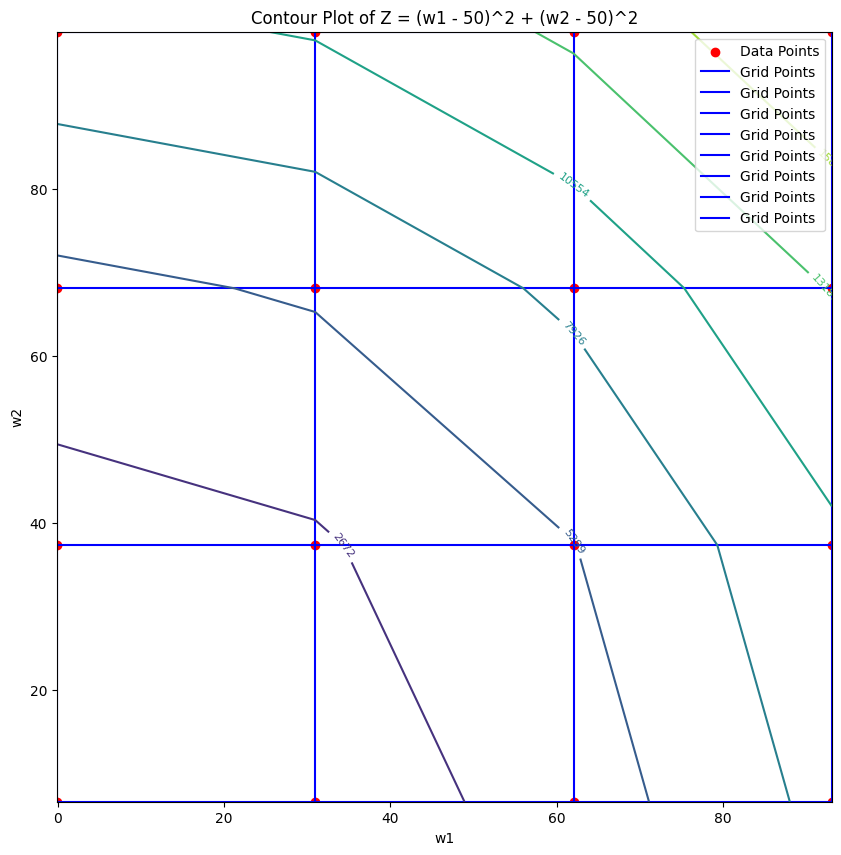

In [24]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


arrayX = np.arange(10)
print('arrayX:', arrayX)

arrayY = np.arange(10, 30, 2)
print('arrayY:', arrayY)


arrayX = np.random.rand(10) * 100
print('arrayX:', arrayX)

arrayY = np.random.rand(10) * 100
print('arrayY:', arrayY)


w1_min, w1_max = arrayX.min() - 0.5, arrayX.max() + 0.5
w2_min, w2_max = arrayY.min() - 0.5, arrayY.max() + 0.5

print('w1_min:', w1_min)
print('w1_max:', w1_max)
print('w2_min:', w2_min)
print('w2_max:', w2_max)

w1_grid = np.linspace(start=w1_min, stop=w1_max, num=4)
w2_grid = np.linspace(start=w2_min, stop=w2_max, num=4)
print('w1_grid:', w1_grid)
print('w2_grid:', w2_grid)

# 求解网格上的函数值 - 以二次函数为例
# Z = np.zeros((len(w1_grid), len(w2_grid)))  # 初始化一个二维数组来存储函数值
# for i in range(len(w1_grid)):
#     for j in range(len(w2_grid)):
#         w1 = w1_grid[i]
#         w2 = w2_grid[j]
#         Z[i, j] = (w1 - 50) ** 2 + (w2 - 50) ** 2  # 以二次函数为例，中心在(50, 50)


# 使用for循环效率较低，直接使用numpy的广播机制来计算函数值
W1, W2 = np.meshgrid(w1_grid, w2_grid) # 创建网格坐标矩阵，W1和W2分别表示网格上每个点的w1和w2值，分别采用横向和纵向的方式进行广播（复制）
Z = (W1) ** 2 + (W2) ** 2

plt.figure(figsize=(10, 10))  # 设置图形大小
plt.scatter(W1, W2, color='red', label='Data Points')  # 在等高线图上绘制数据点，颜色为红色
plt.plot(W1, W2, color='blue', label='Grid Points')  # 在等高线图上绘制网格点，颜色为蓝色
# 矩阵转至

plt.plot(np.transpose(W1), np.transpose(W2) , color='blue', label='Grid Points')
# 绘制等高线图
my_levels = np.linspace(Z.min(), Z.max(), 8)
contour = plt.contour(W1, W2, Z, levels=my_levels, cmap='viridis')  # 绘制等高线图，levels参数设置等高线的数量
plt.clabel(contour, inline=True, fontsize=8)
# plt.colorbar()  # 显示颜色条
plt.xlabel('w1')  # 设置x轴标签
plt.ylabel('w2')  # 设置y轴标签
plt.title('Contour Plot of Z = (w1 - 50)^2 + (w2 - 50)^2')  # 设置图表标题
# plt.scatter(arrayX, arrayY, color='red', label='Data Points')  # 在等高线图上绘制数据点，颜色为红色
plt.legend()  # 显示图例
plt.show()



numpy print options: {'edgeitems': 3, 'threshold': 1000, 'floatmode': 'maxprec', 'precision': 8, 'suppress': False, 'linewidth': 75, 'nanstr': 'nan', 'infstr': 'inf', 'sign': '-', 'formatter': None, 'legacy': False}
w_vis: tensor([[ 0.1317],
        [-0.0039]], requires_grad=True)
b_vis: tensor([0.], requires_grad=True)
   epoch  step        w1        w2         b       loss  grad_norm
0      0     0  0.131678 -0.003877  0.000000  16.133007        NaN
1      1     1  0.170914 -0.128981  0.120154  15.153307   5.928031
2      1     2  0.243133 -0.271970  0.262717  14.005768   7.148075
3      1     3  0.279616 -0.366773  0.370397  13.240204   4.934415
4      1     4  0.339533 -0.474066  0.500724  12.339848   5.970964
x_np: [[-1.1258398  -1.1523602 ]
 [-0.25057858 -0.4338788 ]
 [ 0.84871036  0.69200915]
 ...
 [ 1.6728207  -0.31508678]
 [-0.29654688 -0.35684583]
 [ 0.08291372 -0.51871765]]
w1_grid: [-0.36832169 -0.33934783 -0.31037398 -0.28140012 -0.25242627 -0.22345242
 -0.19447856 -0.1655

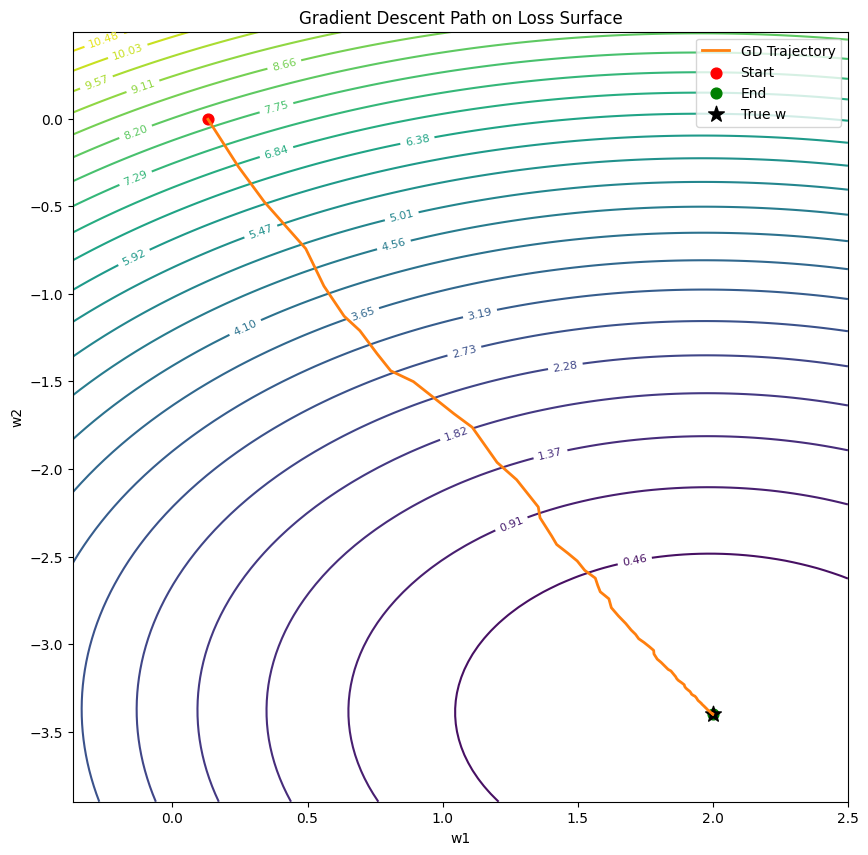

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random # python内置的random模块，用于生成随机数和打乱数据

# torch.set_printoptions(threshold=float('inf'))
# np.set_printoptions(threshold=float('inf'))
# 调整打印长度，恢复默认值
torch.set_printoptions(profile="default") # default表示恢复默认设置
numpy_printoptions = np.get_printoptions() # 获取当前的NumPy打印选项，返回一个包含当前设置的字典
print('numpy print options:', numpy_printoptions) # 打印当前的NumPy打印选项，查看设置的内容

# numpy_print_options = {'edgeitems': 3, 'threshold': 1000, 'floatmode': 'maxprec', 'precision': 8, 'suppress': False, 'linewidth': 75, 'nanstr': 'nan', 'infstr': 'inf', 'sign': '-', 'formatter': None, 'legacy': False}
# np.set_printoptions(**numpy_print_options) # 使用字典解包的方式设置NumPy的打印选项，**numpy_print_options表示将字典中的键值对作为关键字参数传递给set_printoptions函数
# np.set_printoptions(precision=8, threshold=1000, edgeitems=3, linewidth=75, suppress=False, nanstr='nan', infstr='inf', formatter=None)



torch.manual_seed(0) # 设置随机种子，确保每次运行结果相同
def synthetic_data(w, b, num_examples):  #@save
    """生成y=Xw+b+噪声"""
    X = torch.normal(0, 1, (num_examples, len(w))) # 生成均值为0，标准差为1的随机数，形状为(num_examples, len(w))
    # print('X:', X)
    y = torch.matmul(X, w) + b # 矩阵乘法，得到线性关系的结果
    # print('y:', y)
    # print('y shape:', y.shape) # 得到的是一个向量（1维张量）
    y += torch.normal(0, 0.01, y.shape) # 添加噪声，生成的噪声服从均值为0，标准差为0.01）的正态分布，形状与y相同
    # print('y with noise:', y)

    return X, y.reshape((-1, 1)) # 返回特征X和标签y，标签y被重塑为列向量


# 定义模型, 得到预测值
def linreg(X, w, b):  #@save
    """线性回归模型"""
    return torch.matmul(X, w) + b

# 定义损失函数
def squared_loss(y_hat, y):  #@save
    """均方损失"""
    return (y_hat - y.reshape(y_hat.shape)) ** 2 / 2

# 定义优化算法
# 对于每个参数，更新其值，更新的方式是：
# param -= lr * param.grad / batch_size，其中lr是学习率，param.grad是参数的梯度，batch_size是小批量的大小。
def sgd(params, lr, batch_size):  #@save
    """小批量随机梯度下降"""
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad / batch_size
            print('param:', param)
            print('param.grad:', param.grad)
            param.grad.zero_() # 将参数的梯度清零，以便下一次迭代时重新计算梯度

# 在优化算法中，使用torch.no_grad()上下文管理器来禁用梯度计算
# 节省内存（不保存中间结果用于反向传播）
# 加速计算（跳过自动求导机制）
# 避免不必要的梯度累积








true_w = torch.tensor([2.0, -3.4]) # 定义实际权重参数
# 必须至少有一个为float，PyTorch 要求参与运算的两个张量（Tensor）必须是同一种数据类型。
# 列表中有一个浮点数（-3.4），PyTorch 在处理 torch.matmul(X, w) 时，会自动把这个列表转换成 Float (float32) 类型的张量
true_b = 4.2 # 定义实际偏置参数
features, labels = synthetic_data(true_w, true_b, 1000) # 生成1000个样本的特征和标签


X_all = features.detach().float()
y_all = labels.detach().float()



w_vis = torch.normal(0, 0.1, size=(2, 1), requires_grad=True)
print('w_vis:', w_vis)
b_vis = torch.zeros(1, requires_grad=True)
print('b_vis:', b_vis)
lr_vis = 0.03
num_epochs_vis = 20
batch_size_vis = 50

history = [] # 用于记录训练过程中的参数和损失等信息
checkpoints = [] # 用于记录每个 epoch 的参数快照
step = 0 # 记录训练步骤数，用于绘制损失曲线和梯度范数曲线的横轴


# 静默版小批量迭代器（不打印每一步）
def data_iter_silent(batch_size, features, labels):
    num_examples = len(features) # 获取样本数量
    indices = list(range(num_examples)) # 创建一个包含样本索引的列表
    random.shuffle(indices) # 打乱索引列表，确保每次迭代时样本的顺序不同
    for i in range(0, num_examples, batch_size): # 从0开始，以batch_size为步长，遍历样本索引
        batch_indices = torch.tensor(indices[i:min(i + batch_size, num_examples)]) # 获取当前小批量的索引
        yield features[batch_indices], labels[batch_indices] # 通过索引获取对应的特征和标签，并使用yield关键字返回一个生成器对象，每次调用生成器时都会返回一个小批量的数据。


# 保存初始状态
with torch.no_grad():
    init_loss = float(squared_loss(linreg(X_all, w_vis, b_vis), y_all).mean())
    history.append({
        "epoch": 0,
        "step": step,
        "w1": float(w_vis[0, 0]),
        "w2": float(w_vis[1, 0]),
        "b": float(b_vis[0]),
        "loss": init_loss,
        "grad_norm": np.nan,
    })
    checkpoints.append((0, float(w_vis[0, 0]), float(w_vis[1, 0]), float(b_vis[0])))

# 训练模型并记录训练过程中的参数和损失等信息
for epoch in range(1, num_epochs_vis + 1):
    for X_batch, y_batch in data_iter_silent(batch_size_vis, X_all, y_all):
        pred = linreg(X_batch, w_vis, b_vis) # 计算当前小批量的预测值
        batch_loss = squared_loss(pred, y_batch).mean() # 计算当前小批量的损失（平均损失）
        batch_loss.backward() # 反向传播计算梯度（对参数的梯度）

        # print('w_vis.grad:', w_vis.grad) # 打印权重参数的梯度
        # print('b_vis.grad:', b_vis.grad) # 打印偏置参数的梯度
        grad_norm = float(torch.sqrt((w_vis.grad ** 2).sum() + (b_vis.grad ** 2).sum())) # 计算当前小批量的梯度范数，用于监控训练过程中的梯度大小
        # print('grad_norm:', grad_norm) # 打印梯度范数
        # 这里计算梯度范数，是为了把“多个参数的梯度”压缩成一个可监控的标量，便于观察训练动态。

        with torch.no_grad(): # torch.no_grad()上下文管理器来禁用梯度计算，节省内存和计算资源
            w_vis -= lr_vis * w_vis.grad
            b_vis -= lr_vis * b_vis.grad
            w_vis.grad.zero_()
            b_vis.grad.zero_()

            full_loss = float(squared_loss(linreg(X_all, w_vis, b_vis), y_all).mean())

        step += 1
        history.append({
            "epoch": epoch,
            "step": step,
            "w1": float(w_vis[0, 0]),
            "w2": float(w_vis[1, 0]),
            "b": float(b_vis[0]),
            "loss": full_loss,
            "grad_norm": grad_norm,
        })

    # 每个 epoch 记录一次拟合快照
    with torch.no_grad():
        checkpoints.append((epoch, float(w_vis[0, 0]), float(w_vis[1, 0]), float(b_vis[0])))

hist_df = pd.DataFrame(history) # 将训练历史记录转换为 Pandas DataFrame，便于后续分析和可视化
print(hist_df.head()) # 打印训练历史记录的前5行，查看记录的内容和格式



x_np = X_all.numpy() # 将特征张量转换为 NumPy 数组，便于后续计算和可视化
print('x_np:', x_np) # 打印x_np的形状，查看转换后的特征数组的维度
y_np = y_all.squeeze().numpy() # 将标签张量转换为 NumPy 数组，并使用squeeze()方法去除单维度，使其成为一维数组，便于后续计算和可视化

w1_min, w1_max = hist_df["w1"].min() - 0.5, hist_df["w1"].max() + 0.5 # 计算w1的最小值和最大值，并在其基础上扩展0.8的范围，以便在绘制参数空间时有足够的边距 
w2_min, w2_max = hist_df["w2"].min() - 0.5, hist_df["w2"].max() + 0.5 # 计算w2的最小值和最大值，并在其基础上扩展0.8的范围，以便在绘制参数空间时有足够的边距
w1_grid = np.linspace(start=w1_min, stop=w1_max, num=100) # linspace函数用于生成等间距的数值序列，
# start参数指定序列的起始值，stop参数指定序列的结束值，num参数指定生成的数值个数，这里生成100个数值
w2_grid = np.linspace(start=w2_min, stop=w2_max, num=100) 
print('w1_grid:', w1_grid) # 打印w1_grid，查看生成的等间距数值序列
print('w2_grid:', w2_grid) # 打印w2_grid，查看生成的等间距数值序列

print('w1_grid shape:', w1_grid.shape) # 打印w1_grid的形状，查看生成的等间距数值序列的维度

W1, W2 = np.meshgrid(w1_grid, w2_grid) # meshgrid函数用于生成网格坐标矩阵，w1_grid和w2_grid分别是w1和w2的数值序列，




b_fixed = hist_df["b"].iloc[-1] # 使用训练过程中最后一个 epoch 的偏置参数作为固定值，计算损失函数在参数空间中的值
# iloc[-1]表示获取DataFrame中最后一行的数据，这里获取的是最后一个 epoch 的偏置参数值

pred_grid = ( 
    x_np[:, 0][:, None, None] * W1[None, :, :] 
    + x_np[:, 1][:, None, None] * W2[None, :, :] 
    + b_fixed
) # pred_grid的到的结果是一个三维数组，表示在参数空间中每个点对应的预测值。x_np[:, 0]和x_np[:, 1]分别是特征矩阵的第一列和第二列，W1和W2是参数空间的网格坐标矩阵，b_fixed是固定的偏置参数值。通过广播机制，将特征矩阵与网格坐标矩阵进行计算，得到每个参数组合对应的预测值。

# pred_grid全量打印如何设置

print('pred_grid shape:', pred_grid[0].shape)
print('pred_grid shape:', pred_grid.shape) # 打印pred_grid的形状，查看根据网格坐标矩阵计算得到的预测值的维度
print('pred_grid: ', pred_grid) 
print('pred_grid: ', pred_grid[0]) # 打印pred_grid，查看根据网格坐标矩阵计算得到的预测值

Z = ((pred_grid - y_np[:, None, None]) ** 2).mean(axis=0) / 2 # 计算损失函数在参数空间中的值，pred_grid是根据网格坐标矩阵计算得到的预测值，y_np是实际标签值，


plt.figure(figsize=(10, 10))
my_levels = np.linspace(Z.min(), Z.max(), 25)
contour = plt.contour(W1, W2, Z, levels=my_levels, cmap="viridis") # contour函数用于绘制等高线图，W1和W2是参数空间的网格坐标矩阵，Z是损失函数在参数空间中的值，levels参数指定等高线的数量，cmap参数指定颜色映射，这里使用"viridis"颜色映射
# plt.scatter(W1, W2) # scatter函数用于绘制散点图，W1和W2是参数空间的网格坐标矩阵，c参数指定散点的颜色，这里使用Z作为颜色值，cmap参数指定颜色映射，这里使用"viridis"颜色映射，s参数指定散点的大小，edgecolors参数指定散点边缘的颜色，这里设置为黑色
# plt.plot(W1, W2) # plot函数用于绘制线条，W1和W2是参数空间的网格坐标矩阵，color参数指定线条颜色，这里设置为黑色，linewidth参数指定线条宽度，这里设置为0.5
# print(len(W1.shape))
# print(len(W1))
# print(type(W1.shape[1]))
# n, m = W1.shape
# print('n:', n)
# print('m:', m)
# for j in range(W1.shape[1]):
#     plt.plot(W1[:, j], W2[:, j])
# for j in range(len(W1)):
#     plt.plot(W1[j, :], W2[j, :])



plt.clabel(contour, inline=True, fontsize=8) # clabel函数用于在等高线图上添加标签，
# contour参数指定等高线对象，inline参数指定标签是否内嵌在等高线上，fontsize参数指定标签的字体大小
# contour(X, Y, Z) 其实是在表达一个函数：Z = f (X , Y)，contour函数会根据Z的值在X-Y平面上绘制等高线



traj = hist_df.iloc[::max(1, len(hist_df) // 200)] # 从训练历史记录中抽取部分数据点，用于绘制梯度下降轨迹，
# ::max(1, len(hist_df) // 200)表示每隔一定步数抽取一个数据点，确保轨迹图不会过于密集
plt.plot(traj["w1"], traj["w2"], color="#ff7f0e", linewidth=2, label="GD Trajectory") # plot函数用于绘制线条，traj["w1"]和traj["w2"]分别是抽取的数据点的w1和w2参数值，color参数指定线条颜色，linewidth参数指定线条宽度，label参数指定图例标签
plt.scatter(traj["w1"].iloc[0], traj["w2"].iloc[0], color="red", s=60, label="Start")
plt.scatter(traj["w1"].iloc[-1], traj["w2"].iloc[-1], color="green", s=60, label="End")
if "true_w" in globals():
    plt.scatter(float(true_w[0]), float(true_w[1]), color="black", marker="*", s=140, label="True w")
plt.title("Gradient Descent Path on Loss Surface")
plt.xlabel("w1")
plt.ylabel("w2")
plt.legend()
plt.show() 